# 14 — Stratified source-pixel validation sample design

This notebook (1) labels archive observations by whether they have at least one MODIS–VIIRS candidate association under **1 km / 3 h**, processing month-by-month with a three-hour boundary halo; then (2) selects one deterministic Cameroon observation per quarter × satellite × candidate-status stratum and matches each to the closest same-source Level-2 CMR granule by acquisition time and catalog polygon.

A `no candidate` label means no link was found under these thresholds in the ingested archive. It is not a no-fire label or ground-truth negative. The CMR polygon is a catalog extent, not proof of pixel coverage. This notebook creates candidate-presence data and a metadata-only transfer plan. It does not download granules or calculate detection accuracy.

In [1]:
from pathlib import Path
import sys, json, hashlib
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
ROOT=Path.cwd()
if not (ROOT/'data').exists() and (ROOT.parent/'data').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.firewatch.association import find_candidate_links, ASSOCIATION_METHOD_VERSION
from src.firewatch.validation_sampling import select_validation_sample
OBS=ROOT/'data/processed/observations.parquet'
PRESENCE=ROOT/'data/processed/candidate_presence_2025.parquet'
PRESENCE_META=PRESENCE.with_suffix('.metadata.json')
CMR=ROOT/'data/reference/cmr_manifest_2025.csv'
CMR_META=CMR.with_suffix('.metadata.json')
BOUNDARY=ROOT/'data/reference/geoBoundaries-CMR-ADM0-2016.geojson'
cmr_meta=json.loads(CMR_META.read_text(encoding='utf-8'))
assert hashlib.sha256(CMR.read_bytes()).hexdigest()==cmr_meta['manifest_sha256']
print(f"Verified all-year CMR manifest SHA-256: {cmr_meta['manifest_sha256']}")

Verified all-year CMR manifest SHA-256: 6b7d4410af4d895aa087a5fd35560efef2d0c70f9c72aa8b42342098d160f923


In [2]:
# Build cross-platform candidate-presence flags over the complete local 2025 archive.
# Three-hour halos allow associations crossing month boundaries; dates after 2025 are included as halo inputs.
columns=['observation_id','satellite','product_code','latitude_num','longitude_num','observation_datetime_utc','validation_status','stream_type']
all_obs=pd.read_parquet(OBS,columns=columns)
all_obs['observation_datetime_utc']=pd.to_datetime(all_obs.observation_datetime_utc,utc=True)
archive=all_obs.loc[all_obs.stream_type.eq('archive')].copy()
year=archive.loc[archive.observation_datetime_utc.ge('2025-01-01T00:00:00Z')&archive.observation_datetime_utc.lt('2026-01-01T00:00:00Z')].copy()
year['candidate_cross_platform_1km_3h']=False
monthly_diagnostics=[]
for month in range(1,13):
    start=pd.Timestamp(year=2025,month=month,day=1,tz='UTC')
    end=start+pd.offsets.MonthBegin(1)
    window=archive.loc[archive.observation_datetime_utc.ge(start-pd.Timedelta(hours=3))&archive.observation_datetime_utc.lt(end+pd.Timedelta(hours=3))]
    links=find_candidate_links(window,max_distance_km=1.0,max_time_delta_hours=3.0)
    cross=links.loc[links.link_family.eq('MODIS-VIIRS')]
    linked_ids=set(cross.left_observation_id)|set(cross.right_observation_id)
    core_mask=year.observation_datetime_utc.ge(start)&year.observation_datetime_utc.lt(end)
    core_ids=set(year.loc[core_mask,'observation_id'])
    marked=linked_ids & core_ids
    year.loc[year.observation_id.isin(marked),'candidate_cross_platform_1km_3h']=True
    monthly_diagnostics.append({'month':start.strftime('%Y-%m'),'cross_family_candidate_edges':int(len(cross)),'candidate_observations_in_month':len(marked),'window_rows':len(window)})
    print(start.strftime('%Y-%m'), 'MODIS–VIIRS edges:',f'{len(cross):,}','candidate observations:',f'{len(marked):,}',flush=True)
presence=year[['observation_id','satellite','product_code','latitude_num','longitude_num','observation_datetime_utc','validation_status','candidate_cross_platform_1km_3h']].sort_values(['observation_datetime_utc','satellite','observation_id'],kind='stable')
presence.to_parquet(PRESENCE,index=False)
source_sha=hashlib.sha256(OBS.read_bytes()).hexdigest()
pres_meta={'year':2025,'stream_type':'archive','rows':len(presence),'valid_rows':int(presence.validation_status.eq('valid').sum()),'candidate_observation_rows':int(presence.candidate_cross_platform_1km_3h.sum()),'noncandidate_observation_rows':int((~presence.candidate_cross_platform_1km_3h & presence.validation_status.eq('valid')).sum()),'association_threshold_km':1.0,'association_threshold_hours':3.0,'link_family':'MODIS-VIIRS','association_method_version':ASSOCIATION_METHOD_VERSION,'boundary_halo_hours':3,'boundary_handling':'Each month uses archive rows in a 3-hour halo on both sides; only core-month 2025 rows are labeled. The supplied archive starts at 2025-01-01, so earlier boundary observations are not available.','monthly_diagnostics':monthly_diagnostics,'source_observations_parquet_sha256':source_sha,'derived_file':PRESENCE.name,'grain':'one original observation per row; candidate flag indicates one or more thresholded cross-family edges, not an event label'}
PRESENCE_META.write_text(json.dumps(pres_meta,indent=2),encoding='utf-8')
print('Saved candidate-presence rows:',f'{len(presence):,}','| candidate-linked observation rows:',f"{pres_meta['candidate_observation_rows']:,}")

2025-01 MODIS–VIIRS edges: 33,395 candidate observations: 34,085


2025-02 MODIS–VIIRS edges: 47,839 candidate observations: 44,475


2025-03 MODIS–VIIRS edges: 12,149 candidate observations: 12,183


2025-04 MODIS–VIIRS edges: 1,076 candidate observations: 1,066


2025-05 MODIS–VIIRS edges: 394 candidate observations: 398


2025-06 MODIS–VIIRS edges: 243 candidate observations: 221


... (3 outputs left out)

2025-10 MODIS–VIIRS edges: 332 candidate observations: 339


2025-11 MODIS–VIIRS edges: 2,066 candidate observations: 2,218


2025-12 MODIS–VIIRS edges: 10,850 candidate observations: 11,058


Saved candidate-presence rows: 712,234 | candidate-linked observation rows: 106,069


In [3]:
# Select one reproducible row per quarter × platform × status stratum and match catalog granules.
pres_meta=json.loads(PRESENCE_META.read_text(encoding='utf-8'))
manifest=pd.read_csv(CMR)
boundary=json.loads(BOUNDARY.read_text(encoding='utf-8'))
sample,audit=select_validation_sample(presence,manifest,boundary)
matched=sample.loc[sample.selection_status.eq('matched')].copy()
granules=(matched.sort_values(['producer_granule_id','updated_utc'],kind='stable')
          .drop_duplicates('producer_granule_id',keep='last').copy())
assert len(sample)==40, f'Expected 4 quarters × 5 platforms × 2 candidate strata, got {len(sample)} rows'
assert sample.observation_id.dropna().is_unique
assert len(matched)>0
print('Observation strata:',len(sample),'| matched to CMR:',len(matched),'| empty/unmatched:',len(sample)-len(matched))
print('Unique granules:',granules.producer_granule_id.nunique(),'| CMR estimated MB:',round(granules.granule_size_cmr_mb.sum(),3))
display(sample[['quarter','satellite','cross_platform_candidate','stratum_frame_size_cameroon','selection_status','selection_attempts','observation_time_utc','producer_granule_id']].sort_values(['quarter','satellite','cross_platform_candidate']).reset_index(drop=True))
display(granules.groupby(['short_name','platform'],as_index=False).agg(unique_granules=('producer_granule_id','nunique'),estimated_mb=('granule_size_cmr_mb','sum')))

Observation strata: 40 | matched to CMR: 39 | empty/unmatched: 1
Unique granules: 39 | CMR estimated MB: 69.353


,quarter,satellite,cross_platform_candidate,stratum_frame_size_cameroon,selection_status,selection_attempts,observation_time_utc,producer_granule_id
0,Q1,Aqua,False,9907,matched,1.0,2025-03-14T13:25:00+00:00,MYD14.A2025073.1325.061.2025074111146
1,Q1,Aqua,True,19861,matched,1.0,2025-03-04T13:26:00+00:00,MYD14.A2025063.1325.061.2025064102618
2,Q1,N20,False,154751,matched,1.0,2025-03-07T12:45:00+00:00,VJ114IMG.A2025066.1242.002.2025067131905
3,Q1,N20,True,22664,matched,2.0,2025-03-02T12:38:00+00:00,VJ114IMG.A2025061.1236.002.2025061185458
4,Q1,N21,False,151430,matched,4.0,2025-02-09T00:40:00+00:00,VJ214IMG.A2025040.0036.002.2025319142934
5,Q1,N21,True,23357,matched,2.0,2025-01-03T13:20:00+00:00,VJ214IMG.A2025003.1318.002.2025318215015
6,Q1,SNPP,False,156442,matched,1.0,2025-01-31T00:34:00+00:00,VNP14IMG.A2025031.0030.002.2025031095236
7,Q1,SNPP,True,24096,matched,1.0,2025-01-17T12:42:00+00:00,VNP14IMG.A2025017.1242.002.2025017200315
8,Q1,Terra,False,4578,matched,4.0,2025-02-03T09:27:00+00:00,MOD14.A2025034.0925.061.2025034145629
9,Q1,Terra,True,403,matched,1.0,2025-01-16T08:59:00+00:00,MOD14.A2025016.0855.061.2025016143257


,short_name,platform,unique_granules,estimated_mb
0,MOD14,Terra,7,1.779223
1,MYD14,Aqua,8,2.809318
2,VJ114IMG,N20,8,24.136523
3,VJ214IMG,N21,8,18.923377
4,VNP14IMG,SNPP,8,21.704793


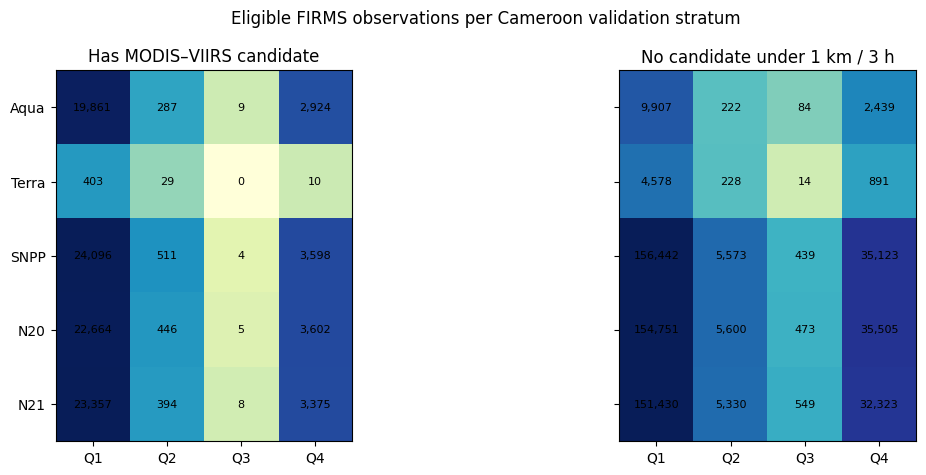

Terra Q3 has no candidate-linked row in the Cameroon frame; the stratum stays explicitly empty.


In [4]:
# Show the available Cameroon frame size in each source/season/status stratum.
fig,axes=plt.subplots(1,2,figsize=(13,4.8),sharey=True)
platforms=['Aqua','Terra','SNPP','N20','N21']; quarters=['Q1','Q2','Q3','Q4']
for ax,status in zip(axes,[True,False]):
    grid=(sample.loc[sample.cross_platform_candidate.eq(status)]
          .pivot(index='satellite',columns='quarter',values='stratum_frame_size_cameroon')
          .reindex(index=platforms,columns=quarters).fillna(0))
    ax.imshow(np.log10(grid.to_numpy()+1),cmap='YlGnBu',vmin=0)
    ax.set_xticks(range(4),quarters); ax.set_yticks(range(5),platforms)
    ax.set_title('Has MODIS–VIIRS candidate' if status else 'No candidate under 1 km / 3 h')
    for i in range(5):
        for j in range(4): ax.text(j,i,f'{int(grid.iloc[i,j]):,}',ha='center',va='center',fontsize=8,color='black')
fig.suptitle('Eligible FIRMS observations per Cameroon validation stratum')
fig.tight_layout(); plt.show()
print('Terra Q3 has no candidate-linked row in the Cameroon frame; the stratum stays explicitly empty.')

In [5]:
# Write a 40-row stratum audit and a deduplicated unique-granule plan.
SAMPLE_OUT=ROOT/'data/reference/validation_sample_2025.csv'
PLAN_OUT=ROOT/'data/reference/validation_granule_plan_2025.csv'
META_OUT=ROOT/'data/reference/validation_sample_2025.metadata.json'
sample.to_csv(SAMPLE_OUT,index=False)
plan_columns=['platform','short_name','collection_version','cmr_entry_id','producer_granule_id','acquisition_id','granule_start_utc','granule_end_utc','updated_utc','granule_center_delta_seconds','reprocessing_variants_for_acquisition','granule_size_cmr_mb','data_url','browse_url']
plan=granules[plan_columns].sort_values(['platform','granule_start_utc','producer_granule_id'],kind='stable').reset_index(drop=True)
plan.to_csv(PLAN_OUT,index=False)
metadata={
 'sampling_design':'One deterministic SHA-256-ranked observation per available Cameroon ADM0 × quarter × satellite × candidate-status stratum.',
 'seed':'firewatch-2025-pixel-validation-v1',
 'candidate_definition':'At least one MODIS–VIIRS candidate link at 1 km / 3 h; non-candidate means no such link in the local archive, not no fire or a true negative.',
 'sample_strata':len(sample),'matched_observations':len(matched),'empty_or_unmatched_strata':int(sample.selection_status.ne('matched').sum()),
 'unique_granules':int(plan.producer_granule_id.nunique()),'cmr_estimated_total_mb':float(plan.granule_size_cmr_mb.sum()),
 'granule_files_downloaded':0,'association_method_version':pres_meta['association_method_version'],
 'input_candidate_presence_sha256':hashlib.sha256(PRESENCE.read_bytes()).hexdigest(),
 'input_candidate_presence_metadata_sha256':hashlib.sha256(PRESENCE_META.read_bytes()).hexdigest(),
 'input_cmr_manifest_sha256':cmr_meta['manifest_sha256'],
 'input_boundary_sha256':hashlib.sha256(BOUNDARY.read_bytes()).hexdigest(),
 'cmr_manifest_metadata_sha256':hashlib.sha256(CMR_META.read_bytes()).hexdigest(),
 'selection_status_counts':sample.selection_status.value_counts(dropna=False).to_dict(),
 'limitations':['FIRMS candidate status is not event identity or truth label.','CMR time and polygons do not prove per-pixel valid observation coverage.','This is a small stratified reader/linkage pilot, not a probability sample for accuracy metrics.','The supplied FIRMS archive begins 2025-01-01, so candidate status near the left boundary lacks earlier observations.','Processing variants are retained in the source manifest; the sample plan selects the latest CMR update for the closest matching acquisition.']
}
META_OUT.write_text(json.dumps(metadata,indent=2),encoding='utf-8')
print('Wrote observation audit:',SAMPLE_OUT.relative_to(ROOT))
print('Wrote unique granule plan:',PLAN_OUT.relative_to(ROOT))
print(json.dumps({k:metadata[k] for k in ['matched_observations','empty_or_unmatched_strata','unique_granules','cmr_estimated_total_mb','granule_files_downloaded']},indent=2))

Wrote observation audit: data\reference\validation_sample_2025.csv
Wrote unique granule plan: data\reference\validation_granule_plan_2025.csv
{
  "matched_observations": 39,
  "empty_or_unmatched_strata": 1,
  "unique_granules": 39,
  "cmr_estimated_total_mb": 69.35323429107666,
  "granule_files_downloaded": 0
}


## Transfer boundary and interpretation

This plan selects **39 unique granules** for about **69.4 MB** of CMR-estimated payload; the remaining Terra Q3 candidate stratum has no eligible observation. The generalized downloader retains a two-file default and has hard limits of 40 files and 100 MB; use explicit limits for the prepared batch. Its per-file checks, redirect credential isolation, checksums, and plan-hash-based resume manifest remain active.

After transfer, notebook 13 can be generalized to compare every sample point with native L2 fire-pixel records and QA masks. Treat the sample as a stratified engineering validation set. Because observations were chosen based partly on candidate status and the study geography, it does not support unbiased precision, recall, false-alarm, or harmonized fire-count estimates.